# Selección de parámetros de PCA y DBSCAN

In [1]:
import os, sys, warnings
sys.path.insert(0, os.path.abspath('..')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from src.utils.config import cargar_config, ruta_csv, carpeta
from src.ingesta import leer_csv
from src.limpieza import limpiar_ejercicio
from src.modelo import construir_variables
from src.evaluacion import sensibilidad_parametros
cfg = cargar_config()
SAL = carpeta(cfg, 'salidas')
C = ['anio','total_bienes_inicio','total_bienes_final','total_deudas_final','total_ingreso_neto_c1234']
partes = []
for a in cfg['proyecto']['ejercicios']:
    out, _, _ = limpiar_ejercicio(leer_csv(ruta_csv(cfg, a), cfg), cfg)
    partes.append(out.loc[out.es_analizada, C].astype('float64'))
df = pd.concat(partes, ignore_index=True); X = construir_variables(df); ok = X.notna().all(axis=1)
Xe, anios = X[ok].to_numpy(), df.loc[ok, 'anio'].astype(int).to_numpy()
print(Xe.shape)

(450880, 4)


## 1. Cantidad de componentes (varianza explicada)

In [2]:
pca = PCA(n_components=0.80, svd_solver='full').fit(Xe)
print('componentes:', pca.n_components_, '| varianza acumulada:', pca.explained_variance_ratio_.sum().round(3))
pd.Series(pca.explained_variance_ratio_, index=range(1, pca.n_components_ + 1))

componentes: 3 | varianza acumulada: 0.888


1    0.423625
2    0.253814
3    0.210465
dtype: float64

## 2. Gráfico de distancias al k-ésimo vecino (un ejercicio)

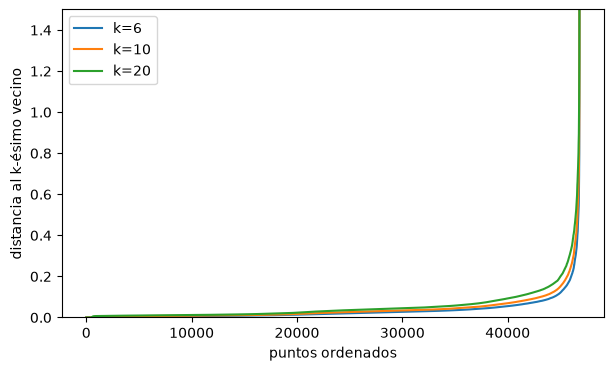

In [3]:
EJERCICIO = 2022
Z = pca.transform(Xe[anios == EJERCICIO])
fig, ax = plt.subplots(figsize=(7, 4))
for k in (6, 10, 20):
    d = np.sort(NearestNeighbors(n_neighbors=k).fit(Z).kneighbors(Z)[0][:, -1])
    ax.plot(d, label=f'k={k}')
ax.set_ylim(0, 1.5); ax.set_xlabel('puntos ordenados'); ax.set_ylabel('distancia al k-ésimo vecino'); ax.legend()
plt.savefig(SAL / 'distancias_k.png', dpi=150)

## 3. Barrido de eps y min_samples (proporción de ruido y clusters)
Las combinaciones con eps grande se omiten solas por memoria (`modelo.max_memoria_gb`).

In [4]:
res = sensibilidad_parametros(Xe, anios, EJERCICIO, [0.08, 0.1, 0.15, 0.2, 0.3], [10, 15, 20], cfg, n_muestra=60000)
res.to_csv(SAL / 'sensibilidad_parametros.csv', index=False)
res

,eps,min_samples,proporcion_ruido,n_clusters,omitido
0,0.08,10,0.084124,38,
1,0.10,10,0.052508,19,
2,0.15,10,0.026275,13,
3,0.20,10,0.015552,14,
4,0.30,10,0.006537,15,
5,0.08,15,0.112685,24,
6,0.10,15,0.072546,19,
7,0.15,15,0.032129,12,
8,0.20,15,0.019845,14,
9,0.30,15,0.008459,16,


## 4. Decisión
Se adoptan eps = 0,15 y min_samples = 10. PCA retiene 3 componentes (88,8 % de varianza), por lo que min_samples = 10 supera la regla de 2 × componentes. En el gráfico de distancias al décimo vecino, el codo se ubica entre 0,10 y 0,20. En el barrido sobre el ejercicio 2022, esta combinación clasifica como ruido el 2,6 % de las declaraciones (13 clústeres), cantidad que permite priorizar la revisión; con eps menores el ruido supera el 5 %, y con eps de 0,30 baja del 1 %. Los resultados son estables frente a min_samples (2,6 % a 3,7 % entre 10 y 20).